Synthesized mock dataset successfully. Preview:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions
0,11.0,91.0,Medium,Medium,Yes,7.0,50.0,Medium,Yes,4.0
1,24.0,91.0,Low,High,No,9.0,NaN,High,Yes,0.0
2,19.0,83.0,Medium,Low,NaN,5.0,50.0,High,Yes,4.0
3,15.0,71.0,Medium,Low,No,7.0,75.0,High,No,4.0
4,12.0,98.0,Medium,Low,Yes,5.0,88.0,High,Yes,0.0



--- Unpruned Model ---
Accuracy: 0.625

--- Pruned Model ---
Accuracy: 0.625


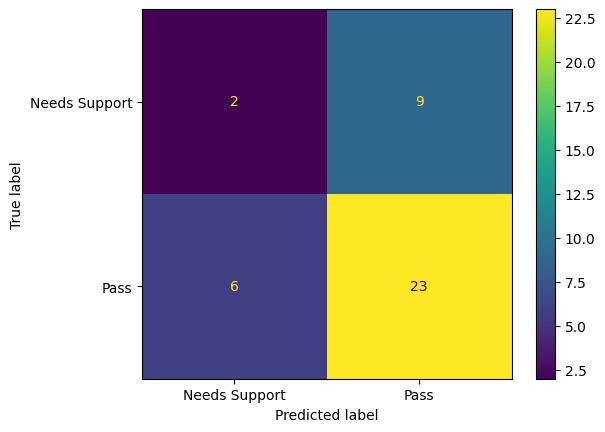

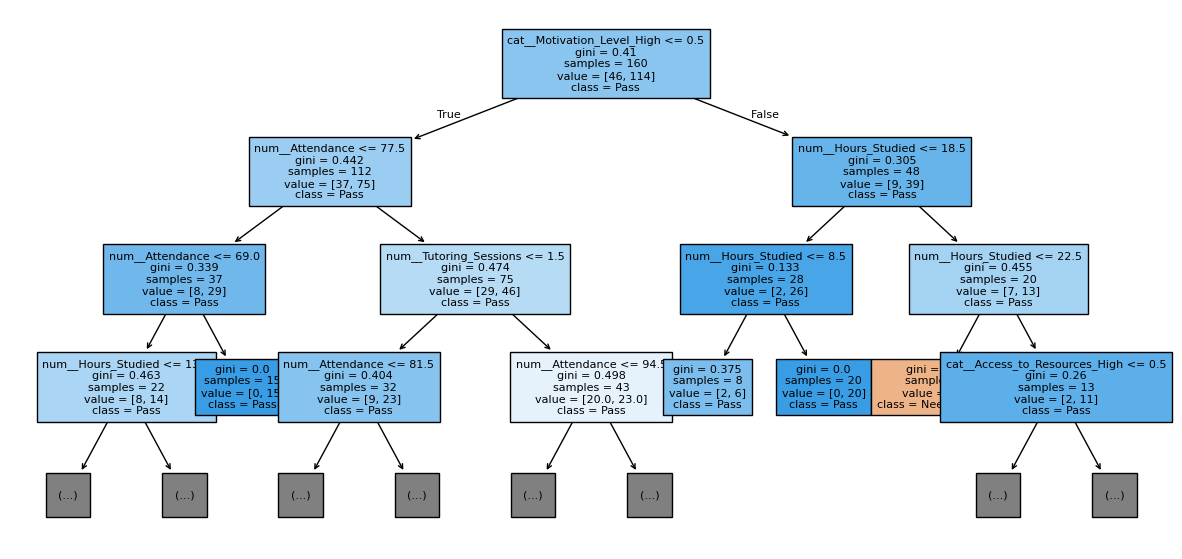

Feature importance:
num__Hours_Studied                  0.422133
num__Attendance                     0.386456
cat__Motivation_Level_High          0.072989
num__Tutoring_Sessions              0.066020
cat__Access_to_Resources_High       0.052402
cat__Parental_Involvement_High      0.000000
cat__Parental_Involvement_Low       0.000000
cat__Parental_Involvement_Medium    0.000000
num__Sleep_Hours                    0.000000
cat__Access_to_Resources_Low        0.000000
dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Creating a realistic mock dataset to bypass the empty file issue
np.random.seed(42)
n_samples = 200

data = {
    "Hours_Studied": np.random.randint(5, 30, size=n_samples),
    "Attendance": np.random.randint(60, 100, size=n_samples),
    "Parental_Involvement": np.random.choice(["High", "Medium", "Low"], size=n_samples, p=[0.3, 0.5, 0.2]),
    "Access_to_Resources": np.random.choice(["High", "Medium", "Low"], size=n_samples, p=[0.4, 0.4, 0.2]),
    "Extracurricular_Activities": np.random.choice(["Yes", "No"], size=n_samples),
    "Sleep_Hours": np.random.randint(5, 10, size=n_samples),
    "Previous_Scores": np.random.randint(40, 100, size=n_samples),
    "Motivation_Level": np.random.choice(["High", "Medium", "Low"], size=n_samples, p=[0.3, 0.5, 0.2]),
    "Internet_Access": np.random.choice(["Yes", "No"], size=n_samples, p=[0.8, 0.2]),
    "Tutoring_Sessions": np.random.randint(0, 5, size=n_samples)
}

df = pd.DataFrame(data)

# Create some random NaNs to test the imputer
for col in df.columns:
    df.loc[df.sample(frac=0.05).index, col] = np.nan

print("Synthesized mock dataset successfully. Preview:")
display(df.head())

# Prepare the dataset target classification
# Impute target variable locally first to avoid NaN in y
median_score = df["Previous_Scores"].median()
df["Previous_Scores"] = df["Previous_Scores"].fillna(median_score)
df["Result"] = np.where(df["Previous_Scores"] >= 60, "Pass", "Needs Support")

X = df.drop(columns=["Previous_Scores", "Result"])
y = df["Result"]

num = X.select_dtypes(include=np.number).columns
cat = X.select_dtypes(exclude=np.number).columns

pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for name, model in [
    ("Unpruned", DecisionTreeClassifier(random_state=42)),
    ("Pruned", DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=5, random_state=42
    ))
]:
    pipe = Pipeline([("pre", pre), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(f"\n--- {name} Model ---")
    print("Accuracy:", accuracy_score(y_test, pred))

    if name == "Pruned":
        ConfusionMatrixDisplay.from_predictions(y_test, pred)
        plt.show()
        names = pipe.named_steps["pre"].get_feature_names_out()
        plt.figure(figsize=(15, 7))
        plot_tree(pipe.named_steps["model"], feature_names=names,
                  class_names=pipe.named_steps["model"].classes_,
                  filled=True, max_depth=3, fontsize=8)
        plt.show()
        print("Feature importance:")
        print(pd.Series(
            pipe.named_steps["model"].feature_importances_,
            index=names
        ).sort_values(ascending=False).head(10))